![Banner](../images/09_04_banner_rs_uav.png)


# Reading and Inspecting UAV Imagery

Most UAV data arrive as folders of plain PNG or JPG frames, not GeoTIFFs: no CRS, no
transform, just pixels.


## Overview

Before any index or model, three jobs come first: read the frames
into a consistent array layout, throw out the bad ones (blur, over- or under-exposure), and
know exactly what is in each folder. This notebook does all three with `rs.uav.read_frame`,
`rs.uav.load_pair`, the quality-control helpers and `rs.uav.build_catalog`.


## Core concepts

### Learning objectives

1. Read PNG frames and RGB + NIR pairs into `(band, y, x)` xarray DataArrays.
2. Distinguish pixel coordinates from map coordinates and attach a GSD.
3. Check bit depth and value ranges.
4. Score frames for blur (variance of the Laplacian) and exposure, and select good frames.
5. Build a tidy catalogue (crop, date, band, rig, path) of a multi-date collection.
6. Extract frames from a flight video.

### Data

| Data | Type |
|---|---|
| LUMS rice, DJI Mini 4 Pro, 11 dates × 10 frames, 3840 × 2160 px RGB PNG (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping`) | **Real** (CC BY 4.0) |
| Paired RGB and NIR PNG crops: Canola, Drybean, Wheat, Lentil-Wheat (`data/`) | **Real**, teaching only (no licence, sensor or GSD on file) |

### Contents

1. Setup
2. What is inside a PNG frame?
3. Reading frames into xarray
4. RGB + NIR pairs
5. Quality control: blur and exposure
6. A tidy catalogue of the whole collection
7. Extracting frames from a flight video
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
from PIL import Image  # inspect raw image files

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")  # data folder next to this notebook
LUMS = DATA / "infrastructure-free-uav-phenotyping"  # LUMS rice frames
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)  # results written by the notebooks

## What is inside a PNG frame?

Look at the file before reading it: size, colour mode and data type tell you the bit depth.


In [2]:
files = {
    "LUMS rice RGB": sorted((LUMS / "2025-08-22").glob("*.png"))[0],
    "Canola RGB": DATA / "Canola dataset/canola_06082019/RGB/5.png",
    "Canola NIR": DATA / "Canola dataset/canola_06082019/NIR/5.png",
}
rows = []
for label, f in files.items():
    with Image.open(f) as im:
        a = np.asarray(im)
        rows.append({"file": label, "size (w x h)": im.size, "mode": im.mode, "dtype": a.dtype,
                     "min": a.min(), "max": a.max(), "MB": round(f.stat().st_size / 1e6, 2)})
pd.DataFrame(rows)

,file,size (w x h),mode,dtype,min,max,MB
0,LUMS rice RGB,"(3840, 2160)",RGB,uint8,0,255,15.10
1,Canola RGB,"(1098, 797)",RGB,uint8,12,255,1.82
2,Canola NIR,"(1099, 798)",RGB,uint8,39,255,1.76


All are 8-bit (`uint8`, 0-255). Note that the NIR file is stored as a 3-channel RGB PNG:
the NIR camera's single band was written to all three channels. `load_pair` collapses it
with `nir_channel="mean"`. Radiometric cameras (MicaSense, DJI P4M) instead write 12- or
16-bit TIFFs, where 255 is not the maximum.


## Reading frames into xarray

`rs.uav.read_frame` returns a `(band, y, x)` DataArray scaled to 0-1, the same layout used
for satellite imagery elsewhere in GeoLattice. Without a GSD the coordinates are pixel centres.
With a GSD they are metres in a local, north-up frame whose origin is the top-left corner.


In [3]:
f = files["LUMS rice RGB"]
img_px = rs.uav.read_frame(f)  # pixel coordinates
img_m = rs.uav.read_frame(f, gsd=0.00185)  # metre coordinates (1.85 mm/px)
print(img_px.dims, img_px.shape, img_px.band.values, img_px.dtype)
print("pixel x:", img_px.x.values[:3], "...  metre x:", img_m.x.values[:3].round(5), "...")
print("attributes:", img_m.attrs)

('band', 'y', 'x') (3, 2160, 3840) ['red' 'green' 'blue'] float32
pixel x: [0.5 1.5 2.5] ...  metre x: [0.00092 0.00278 0.00463] ...
attributes: {'source': 'data/infrastructure-free-uav-phenotyping/2025-08-22/frame1123.png', 'gsd_m': 0.00185, 'units_xy': 'm'}


Converting between pixel (row, col) and map (x, y) coordinates uses an affine transform. For
a frame read with a GSD it is a simple scale; `rs.uav.pix_to_map` and `rs.uav.map_to_pix`
handle any transform, including real GeoTIFF orthomosaics.


In [4]:
from affine import Affine  # 2-D affine transforms (as used by rasterio)

T = Affine(0.00185, 0, 0, 0, -0.00185, 0)  # top-left origin, 1.85 mm pixels, y points up
x, y = rs.uav.pix_to_map(T, np.array([0.5, 1919.5]), np.array([0.5, 1079.5]))  # col, row of two pixels
print("map x:", x.round(4), " map y:", y.round(4))
col, row = rs.uav.map_to_pix(T, x, y)
print("back to pixels: col", np.round(col, 2), " row", np.round(row, 2))

map x: [9.0000e-04 3.5511e+00]  map y: [-9.0000e-04 -1.9971e+00]
back to pixels: col [5.0000e-01 1.9195e+03]  row [5.0000e-01 1.0795e+03]


Large frames can be read downsized for previews and quality checks with `max_dim`; the GSD is
adjusted to match.


(3, 540, 960) GSD now 7.4 mm | x spacing: 7.4 mm


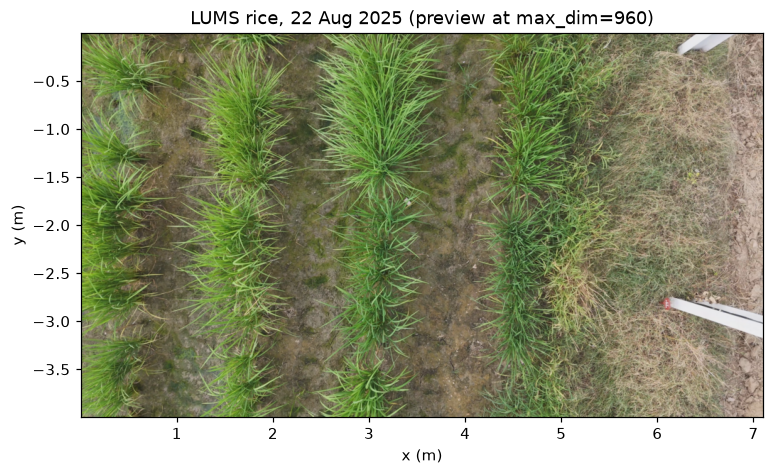

In [5]:
small = rs.uav.read_frame(f, gsd=0.00185, max_dim=960)
print(small.shape, "GSD now", round(small.attrs.get("gsd_m", np.nan) * 1000, 2), "mm" if "gsd_m" in small.attrs else "",
      "| x spacing:", round(float(small.x[1] - small.x[0]) * 1000, 2), "mm")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.imshow(rs.uav.to_rgb_array(small), extent=[float(small.x.min()), float(small.x.max()), float(small.y.min()), float(small.y.max())])
ax.set(xlabel="x (m)", ylabel="y (m)", title="LUMS rice, 22 Aug 2025 (preview at max_dim=960)")
plt.show()

## RGB + NIR pairs

The crop datasets were taken with two cameras side by side, so each frame has an RGB and a
NIR file. `rs.uav.load_pair` stacks them as bands `red, green, blue, nir`, resizing NIR to
the RGB grid. The cameras do not see exactly the same footprint; the false-colour composite
and the edge overlay below show how far apart they are before co-registration (notebook
09_04_05 aligns them).


['red' 'green' 'blue' 'nir'] (4, 797, 1098)


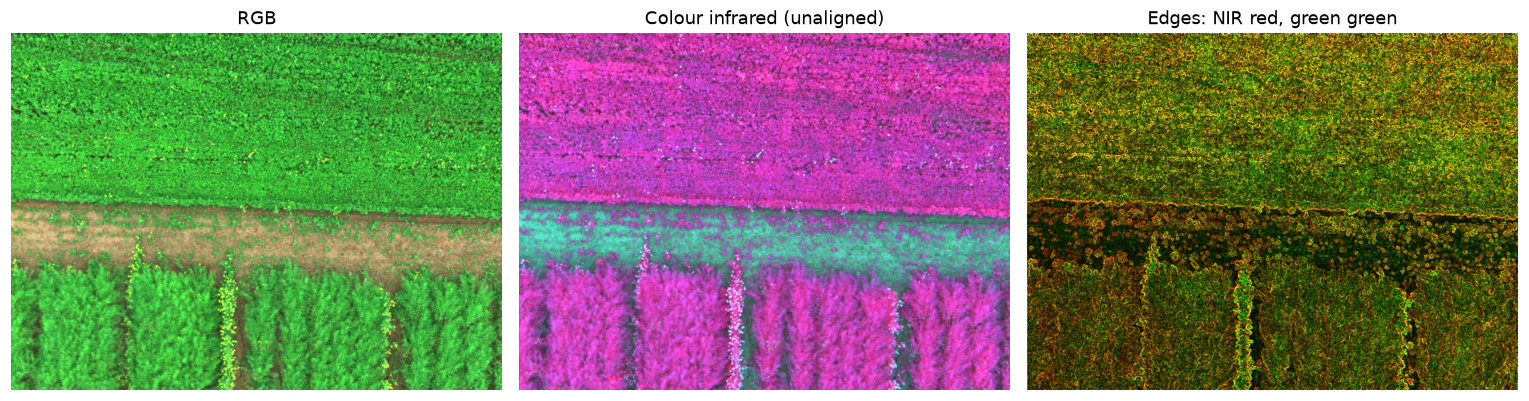

In [6]:
pair = rs.uav.load_pair(files["Canola RGB"], files["Canola NIR"], register=False)
print(pair.band.values, pair.shape)

def edges(a):
    """Gradient magnitude, rescaled to 0-1 (for overlays)."""
    gy, gx = np.gradient(a)
    m = np.hypot(gx, gy)
    return np.clip(m / np.percentile(m, 99), 0, 1)

g = pair.sel(band="green").values; n = pair.sel(band="nir").values
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].imshow(rs.uav.to_rgb_array(pair)); axes[0].set_title("RGB")
cir = np.dstack([n, pair.sel(band="red").values, g])  # colour infrared: NIR, red, green
axes[1].imshow(np.clip(cir / np.percentile(cir, 99.5), 0, 1)); axes[1].set_title("Colour infrared (unaligned)")
axes[2].imshow(np.dstack([edges(n), edges(g), np.zeros_like(g)])); axes[2].set_title("Edges: NIR red, green green")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Where the red and green edges do not coincide (yellow only where they do), the NIR frame is
offset from the RGB frame. Any index that mixes NIR with visible bands (NDVI, GNDVI) is wrong
at those pixels until the pair is co-registered.


## Quality control: blur and exposure

**Blur.** The variance of the Laplacian measures how much fine detail a frame holds: motion
blur and defocus lower it. **Exposure.** The fractions of near-black and near-saturated pixels
flag dark or blown-out frames. `rs.uav.frame_quality` computes both for many files at once.


In [7]:
lums_files = sorted(LUMS.rglob("*.png"))
q = rs.uav.frame_quality(lums_files, max_dim=1024)
q["date"] = [Path(p).parent.name for p in q.path]
print(len(q), "LUMS frames scored")
q.drop(columns="path").describe().round(3)

110 LUMS frames scored


,blur,mean,std,dark_frac,saturated_frac
count,110.000,110.000,110.000,110.0,110.0
mean,579.875,0.428,0.159,0.0,0.0
std,147.999,0.030,0.023,0.0,0.0
min,306.667,0.373,0.109,0.0,0.0
25%,465.480,0.406,0.138,0.0,0.0
50%,582.354,0.428,0.162,0.0,0.0
75%,698.247,0.450,0.180,0.0,0.0
max,913.390,0.499,0.196,0.0,0.0


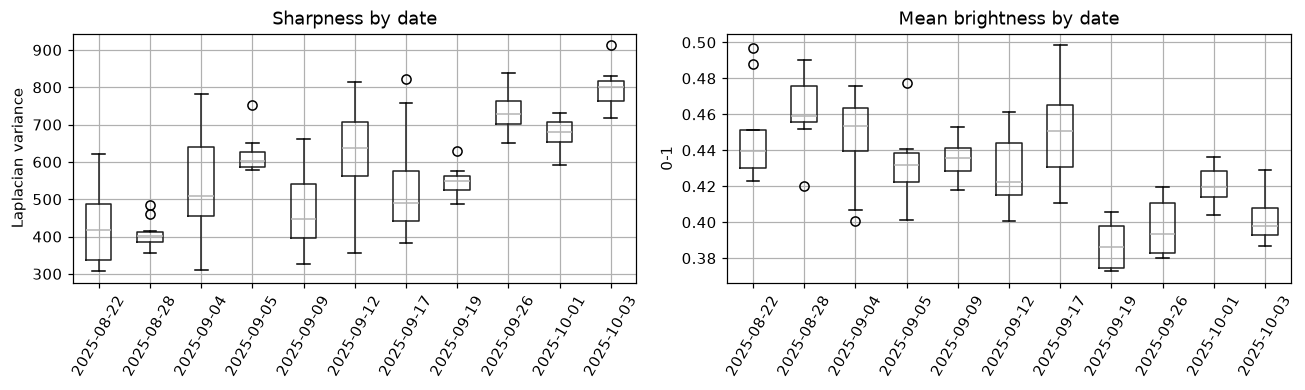

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
q.boxplot(column="blur", by="date", ax=axes[0], rot=60); axes[0].set(title="Sharpness by date", ylabel="Laplacian variance", xlabel="")
q.boxplot(column="mean", by="date", ax=axes[1], rot=60); axes[1].set(title="Mean brightness by date", ylabel="0-1", xlabel="")
plt.suptitle(""); plt.tight_layout(); plt.show()

A synthetic test shows what the blur score responds to: blurring the same frame step by step
lowers it quickly. Note the last row, though: the score is a variance, so it scales with the
square of image contrast, and halving the brightness quarters it. A dull, overcast flight
therefore scores lower than a sunny one without being any less sharp.


In [9]:
from scipy.ndimage import gaussian_filter, shift  # blur and motion simulation

base = rs.uav.read_frame(lums_files[0], max_dim=1024)
rgb = rs.uav.to_rgb_array(base)
tests = {"original": rgb,
         "defocus sigma=1": gaussian_filter(rgb, (1, 1, 0)),
         "defocus sigma=3": gaussian_filter(rgb, (3, 3, 0)),
         "motion 8 px": np.mean([shift(rgb, (0, s, 0), order=0, mode="nearest") for s in range(8)], axis=0),
         "darker x0.5": rgb * 0.5}
res = pd.DataFrame({k: {"blur": rs.uav.blur_score(v), **rs.uav.exposure_stats(v)} for k, v in tests.items()}).T
res.round(4)

,blur,mean,std,dark_frac,saturated_frac
original,331.1176,0.4512,0.1236,0.0,0.0
defocus sigma=1,14.0087,0.4512,0.1037,0.0,0.0
defocus sigma=3,0.1349,0.4512,0.0898,0.0,0.0
motion 8 px,40.1220,0.4507,0.1017,0.0,0.0
darker x0.5,82.7794,0.2256,0.0618,0.0,0.0


Blur scores depend on scene content (a frame of bare soil is less detailed than one of dense
canopy) and on illumination, so thresholds work best **relative to the flight**: keep frames
above, say, half the median score of their own date.


keep
True    110


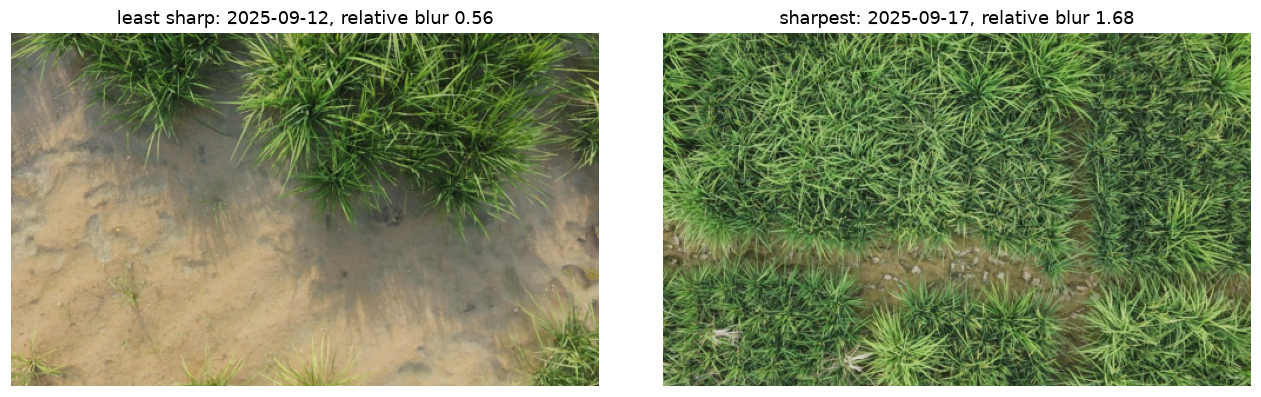

In [10]:
q["blur_rel"] = q.blur / q.groupby("date").blur.transform("median")
q["keep"] = (q.blur_rel >= 0.5) & (q.dark_frac < 0.2) & (q.saturated_frac < 0.05)
print(q.keep.value_counts().to_string())  # the public LUMS frames were already hand-picked
worst = q.sort_values("blur_rel").iloc[0]; best = q.sort_values("blur_rel").iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, r, t in [(axes[0], worst, "least sharp"), (axes[1], best, "sharpest")]:
    im = rs.uav.to_rgb_array(rs.uav.read_frame(r.path, max_dim=1024))
    ax.imshow(im[150:450, 300:800]); ax.axis("off")
    ax.set_title(f"{t}: {r.date}, relative blur {r.blur_rel:.2f}")
plt.tight_layout(); plt.show()

The same check on a random sample of crop RGB frames:


In [11]:
cat = rs.uav.build_catalog(DATA)  # every image under data/
crop_rgb = cat[(cat.band == "RGB") & ~cat.dataset.str.startswith("infra")]
sample = crop_rgb.groupby("crop").sample(15, random_state=0)  # 15 random frames per crop
qc = rs.uav.frame_quality(sample.path.tolist(), max_dim=1100)
qc = qc.merge(sample[["path", "crop", "session"]], on="path")
qc.groupby("crop")[["blur", "mean", "dark_frac", "saturated_frac"]].median().round(3)

,blur,mean,dark_frac,saturated_frac
crop,,,,
canola,89.165,0.342,0.0,0.0
drybean,47.137,0.554,0.0,0.0
lentwheat,36.698,0.442,0.0,0.0
wheat,67.320,0.359,0.0,0.0


## A tidy catalogue of the whole collection

`rs.uav.build_catalog` walks the folder tree once and returns one row per image with
`dataset, crop, session, date, band, rig, frame, path`. Dates are parsed from folder names
in either `YYYY-MM-DD` or `DDMMYYYY` form. The LUMS folders carry only a date, so their crop
is filled in by hand.


In [12]:
cat.loc[cat.dataset.str.startswith("infra"), "crop"] = "rice"
print(len(cat), "images;", cat.session.nunique(), "sessions")
cat.head()

18050 images; 26 sessions


,dataset,crop,session,date,band,rig,frame,path
0,Canola dataset,canola,canola-26072019,2019-07-26,NIR,,0,data/Canola dataset/canola-26072019/NIR/0.png
1,Canola dataset,canola,canola-26072019,2019-07-26,NIR,,1,data/Canola dataset/canola-26072019/NIR/1.png
2,Canola dataset,canola,canola-26072019,2019-07-26,NIR,,10,data/Canola dataset/canola-26072019/NIR/10.png
3,Canola dataset,canola,canola-26072019,2019-07-26,NIR,,100,data/Canola dataset/canola-26072019/NIR/100.png
4,Canola dataset,canola,canola-26072019,2019-07-26,NIR,,101,data/Canola dataset/canola-26072019/NIR/101.png


In [13]:
summary = (cat.groupby(["crop", "date", "band"]).size().unstack("band", fill_value=0)
           .reset_index().sort_values(["crop", "date"]))
summary

band,crop,date,NIR,RGB
0,canola,2018-07-30,313,313
1,canola,2018-08-31,371,371
2,canola,2019-07-26,553,553
3,canola,2019-08-06,73,73
4,drybean,2020-06-14,649,649
5,drybean,2020-06-25,416,416
6,drybean,2020-07-04,433,433
7,drybean,2020-07-30,390,390
8,drybean,2020-08-06,739,739
9,drybean,2020-08-20,728,728


Some sessions were flown with two camera rigs (`RGB-1`/`NIR-1` and `RGB-2`/`NIR-2` in the
Drybean set). Both rigs number their frames from 0, so pairs must be matched **within** a
rig; `rs.uav.pair_catalog` does this using the `rig` column.


In [14]:
pairs = rs.uav.pair_catalog(cat)
print(len(pairs), "RGB/NIR pairs")
pairs.groupby(["crop", "session", "rig"]).size().rename("pairs").reset_index()

8970 RGB/NIR pairs


,crop,session,rig,pairs
0,canola,canola-26072019,,553
1,canola,canola_06082019,,73
2,canola,canola_30072018,,313
3,canola,canola_31082018,,371
4,drybean,drybean-04072020,1,433
5,drybean,drybean-06082020,1,343
6,drybean,drybean-06082020,2,396
7,drybean,drybean-14062020,1,371
8,drybean,drybean-14062020,2,278
9,drybean,drybean-20082020,1,381


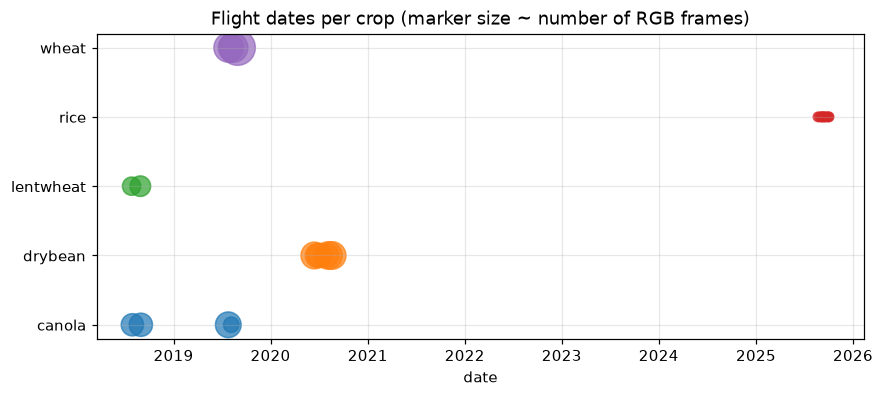

saved outputs/uav_catalog.csv and outputs/uav_pairs.csv


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (crop, d) in enumerate(cat[cat.band == "RGB"].groupby("crop")):
    n = d.groupby("date").size()
    ax.scatter(n.index, np.full(len(n), i), s=np.sqrt(n.values) * 12, alpha=0.7)
ax.set_yticks(range(cat.crop.nunique())); ax.set_yticklabels(sorted(cat.crop.unique()))
ax.set(title="Flight dates per crop (marker size ~ number of RGB frames)", xlabel="date")
ax.grid(alpha=0.3); plt.show()

cat.to_csv(OUT / "uav_catalog.csv", index=False)
pairs.to_csv(OUT / "uav_pairs.csv", index=False)
print("saved", OUT / "uav_catalog.csv", "and", OUT / "uav_pairs.csv")

## Extracting frames from a flight video

LUMS recorded 4K video and kept every 6th frame. `rs.uav.extract_frames` does this and can
drop blurred frames on the way. No video ships with the data, so the cell below makes a short
clip that pans across one frame (with a few deliberately blurred frames) and then extracts
from it.


In [16]:
import cv2  # OpenCV video writing

clip = OUT / "demo_flight.mp4"
src = rs.uav.to_rgb_array(rs.uav.read_frame(lums_files[0]), uint8=True)
h, w = 360, 640
vw = cv2.VideoWriter(str(clip), cv2.VideoWriter_fourcc(*"mp4v"), 24, (w, h))
for i in range(72):  # 3 s at 24 fps, panning right
    x0 = 20 * i
    fr = cv2.resize(src[400:400 + 1080, x0:x0 + 1920], (w, h), interpolation=cv2.INTER_AREA)
    if 30 <= i < 42:  # a gust: motion blur
        fr = cv2.blur(fr, (15, 1))
    vw.write(cv2.cvtColor(fr, cv2.COLOR_RGB2BGR))
vw.release()

frames = rs.uav.extract_frames(clip, OUT / "demo_frames", step=6)
print(len(frames), "frames kept of 72 (every 6th)")
frames.round(3)

12 frames kept of 72 (every 6th)


,frame,time_s,blur,path
0,0,0.00,483.686,outputs/demo_frames/frame0.png
1,6,0.25,427.684,outputs/demo_frames/frame6.png
2,12,0.50,494.263,outputs/demo_frames/frame12.png
3,18,0.75,410.930,outputs/demo_frames/frame18.png
4,24,1.00,498.520,outputs/demo_frames/frame24.png
5,30,1.25,40.974,outputs/demo_frames/frame30.png
6,36,1.50,38.273,outputs/demo_frames/frame36.png
7,42,1.75,513.610,outputs/demo_frames/frame42.png
8,48,2.00,614.614,outputs/demo_frames/frame48.png
9,54,2.25,526.128,outputs/demo_frames/frame54.png


In [17]:
kept = rs.uav.extract_frames(clip, OUT / "demo_frames_sharp", step=6, min_blur=0.5 * frames.blur.median())
print("with min_blur:", len(kept), "frames kept; dropped", sorted(set(frames.frame) - set(kept.frame)))

with min_blur: 10 frames kept; dropped [30, 36]


## Summary and exercises

**Key points**

- Most UAV frames are PNG or JPG files with no CRS. Read them to `(band, y, x)` and attach a
  GSD when you know one.
- Blur (variance of the Laplacian) and exposure scores are the first filter. A frame that
  fails them should not enter an index or a mosaic.
- `build_catalog` and `pair_catalog` turn a folder of dates, crops and bands into one table.
- `extract_frames` turns a mapping video into stills and can drop blurred frames while it
  writes them.

**GeoLattice functions used:** `rs.uav.read_frame`, `rs.uav.load_pair`, `rs.uav.pix_to_map`,
`rs.uav.map_to_pix`, `rs.uav.frame_quality`, `rs.uav.blur_score`, `rs.uav.exposure_stats`,
`rs.uav.build_catalog`, `rs.uav.pair_catalog`, `rs.uav.extract_frames`.

**Exercises**

1. Read one Wheat pair with `load_pair` and make the colour-infrared composite. Is the offset
   between cameras larger or smaller than in Canola?
2. Run `frame_quality` on all frames of `canola_06082019`. Which frames would you drop with the
   relative-blur rule? Look at them.
3. Add a column `doy` (day of year) to the catalogue and plot frames per crop against `doy`.
   Which crops overlap in season?
4. `extract_frames` names files by frame index. Change the demo to keep every 12th frame and
   compute the ground spacing between kept frames for a 1 m/s flight.

**References**

- Pech-Pacheco, J. L. et al. (2000). Diatom autofocusing in brightfield microscopy: a
  comparative study. *ICPR 2000* (variance-of-Laplacian focus measure).
- Chaudhry, H., Rana, S. and Jaleel, A. (2026). UAV-based crop reconstruction and trait
  estimation using RGB imagery without external geospatial infrastructure. *Computers and
  Electronics in Agriculture* (accepted).
